# Online Retail: Preprocessing, Data Warehouse, OLAP and Churn Prediction
**Dataset:** UCI Online Retail (`data.csv`)

1. Setup and loading
2. Exploration
3. Cleaning
4. Outlier detection
5. Star schema
6. OLAP operations
7. Sales analysis
8. Customer analysis (RFM, clustering, cohorts)
9. Market basket analysis
10. Churn prediction
11. Data quality checks and export

## 1. Setup and loading

In [24]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import sparse
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score,
                             classification_report, f1_score, precision_score,
                             recall_score, roc_auc_score, silhouette_score)
from sklearn.model_selection import (StratifiedKFold, cross_val_predict,
                                     cross_val_score, train_test_split)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

sns.set_theme(style="whitegrid")
SEED = 42

In [25]:
# Looks for data.csv: DATA_PATH variable, the Kaggle input folder, then the current folder
candidates = [os.environ.get("DATA_PATH", ""),
              "/kaggle/input/datasets/carrie1/ecommerce-data/data.csv",
              *glob.glob("/kaggle/input/**/data.csv", recursive=True),
              "data.csv"]
file_path = next((p for p in candidates if p and os.path.exists(p)), None)
if file_path is None:
    raise FileNotFoundError("data.csv not found. Set the DATA_PATH environment variable.")

df = pd.read_csv(file_path, encoding="ISO-8859-1",
                 dtype={"InvoiceNo": str, "StockCode": str})
df.columns = df.columns.str.strip()
print("Loaded:", file_path)
print("Shape:", df.shape)
df.head()

Loaded: /kaggle/input/datasets/carrie1/ecommerce-data/data.csv
Shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## 2. Exploration

In [26]:
display(df.tail())
display(df.dtypes)
display(df.describe(include="all").T)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,12/9/2011 12:50,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France


InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
InvoiceNo,541909,25900,573585,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,218.081158,-80995.0,1.0,3.0,10.0,80995.0
InvoiceDate,541909,23260,10/31/2011 14:41,1114,NaN,NaN,NaN,NaN,NaN,NaN,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,96.759853,-11062.06,1.25,2.08,4.13,38970.0
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,1713.600303,12346.0,13953.0,15152.0,16791.0,18287.0
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Percent
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Duplicate records: 5268


CustomerID     4372
StockCode      4070
Country          38
InvoiceNo     25900
Name: Unique values, dtype: int64

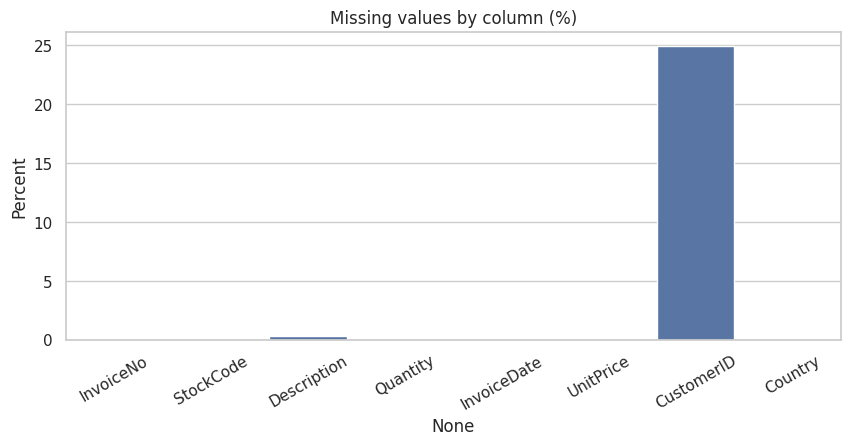

In [27]:
missing = pd.DataFrame({"Missing": df.isnull().sum(),
                        "Percent": (df.isnull().mean() * 100).round(2)})
display(missing)
print("Duplicate records:", df.duplicated().sum())
display(df[["CustomerID", "StockCode", "Country", "InvoiceNo"]].nunique().rename("Unique values"))

plt.figure(figsize=(10, 4))
sns.barplot(x=missing.index, y=missing["Percent"])
plt.title("Missing values by column (%)")
plt.xticks(rotation=30)
plt.show()

## 3. Cleaning

In [ ]:
df_clean = df.drop_duplicates().copy()
print("Duplicates removed:", len(df) - len(df_clean))

df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], format="%m/%d/%Y %H:%M",
                                         errors="coerce")
for col in ["Quantity", "UnitPrice", "CustomerID"]:
    df_clean[col] = pd.to_numeric(df_clean[col], errors="coerce")
df_clean["CustomerID"] = df_clean["CustomerID"].astype("Int64")
df_clean["StockCode"] = df_clean["StockCode"].str.strip().str.upper()
df_clean = df_clean.dropna(subset=["StockCode", "InvoiceDate", "Quantity", "UnitPrice"])

# One standard description per product (the most frequent one)
description_map = (df_clean.dropna(subset=["Description"])
                   .groupby("StockCode")["Description"]
                   .agg(lambda s: s.str.strip().mode().iat[0]))
df_clean["Description"] = df_clean["StockCode"].map(description_map).fillna("Unknown Product")
df_clean["Country"] = df_clean["Country"].fillna("Unspecified")
df_clean["IsCancelled"] = df_clean["InvoiceNo"].str.startswith("C")
print("Clean rows:", len(df_clean))

### 3.1 Non-product codes
Product codes start with five digits, or with DCGS when they have a product description.

In [28]:
is_numbered = df_clean["StockCode"].str.match(r"^\d{5}")
is_dcgs = (df_clean["StockCode"].str.startswith("DCGS")
           & ~df_clean["Description"].str.lower().isin(["ebay", "unknown product"]))
is_product = is_numbered | is_dcgs

display(df_clean[~is_product].groupby("StockCode")
        .agg(Description=("Description", "first"), Rows=("InvoiceNo", "size"))
        .sort_values("Rows", ascending=False))
products_only = df_clean[is_product]

,Description,Rows
StockCode,,
POST,POSTAGE,1256
DOT,DOTCOM POSTAGE,710
M,Manual,567
C2,CARRIAGE,144
D,Discount,77
S,SAMPLES,62
BANK CHARGES,Bank Charges,37
AMAZONFEE,AMAZON FEE,34
CRUK,CRUK Commission,16


### 3.2 Netting cancellations against purchases
Removing only the cancellation rows leaves the reversed purchase in the sales data. Each cancellation
is matched to earlier purchases with the same customer, product and price (latest first), and the
cancelled quantity is subtracted. Cancellations with no match (for example, no customer ID, or a
purchase made before the data starts) are counted and left out.

In [29]:
sales_raw = products_only[~products_only["IsCancelled"]
                          & (products_only["Quantity"] > 0)
                          & (products_only["UnitPrice"] > 0)]
cancels = products_only[products_only["IsCancelled"] & (products_only["Quantity"] < 0)]


def net_cancellations(sales, cancellations):
    """Return (net sales, matched units, total cancelled units)."""
    sales = sales.sort_values("InvoiceDate", kind="stable").reset_index(drop=True)
    cancellations = cancellations.dropna(subset=["CustomerID"]).sort_values("InvoiceDate", kind="stable")
    keys = ["CustomerID", "StockCode", "UnitPrice"]
    relevant = sales.dropna(subset=["CustomerID"]).merge(
        cancellations[keys].drop_duplicates().astype({"CustomerID": "Int64"}),
        on=keys, how="left", indicator=True)
    relevant.index = sales.index[sales["CustomerID"].notna()]
    relevant = relevant[relevant["_merge"] == "both"]
    lookup = {k: list(g.index) for k, g in relevant.groupby(keys)}

    quantity = sales["Quantity"].to_numpy().copy()
    dates = sales["InvoiceDate"].to_numpy()
    matched = 0
    for row in cancellations.itertuples():
        remaining = -row.Quantity
        when = row.InvoiceDate.to_datetime64()
        for i in reversed(lookup.get((row.CustomerID, row.StockCode, row.UnitPrice), [])):
            if remaining <= 0:
                break
            if dates[i] <= when and quantity[i] > 0:
                used = min(quantity[i], remaining)
                quantity[i] -= used
                remaining -= used
                matched += used
    sales["Quantity"] = quantity
    sales = sales[sales["Quantity"] > 0].copy()
    sales["TotalAmount"] = sales["Quantity"] * sales["UnitPrice"]
    return sales, int(matched), int(-cancellations["Quantity"].sum())


df_sales, matched_units, cancelled_units = net_cancellations(sales_raw, cancels)
gross = (sales_raw["Quantity"] * sales_raw["UnitPrice"]).sum()
print(f"Gross product revenue: {gross:,.2f}")
print(f"Net product revenue:   {df_sales['TotalAmount'].sum():,.2f}")
print(f"Cancelled units matched: {matched_units:,} of {cancelled_units:,} (with customer ID)")
print("Cancellation rows without customer ID:", cancels["CustomerID"].isna().sum())
print("Sales rows:", len(df_sales))

Gross product revenue: 10,247,219.32
Net product revenue:   9,804,875.19
Cancelled units matched: 246,441 of 267,711 (with customer ID)
Cancellation rows without customer ID: 162
Sales rows: 519815


## 4. Outlier detection
IQR flags are kept as information. Rows are not removed, since high prices and bulk orders can be genuine.

UnitPrice: bounds [-3.07, 8.45], outliers 35,289
Quantity: bounds [-14.00, 26.00], outliers 26,653


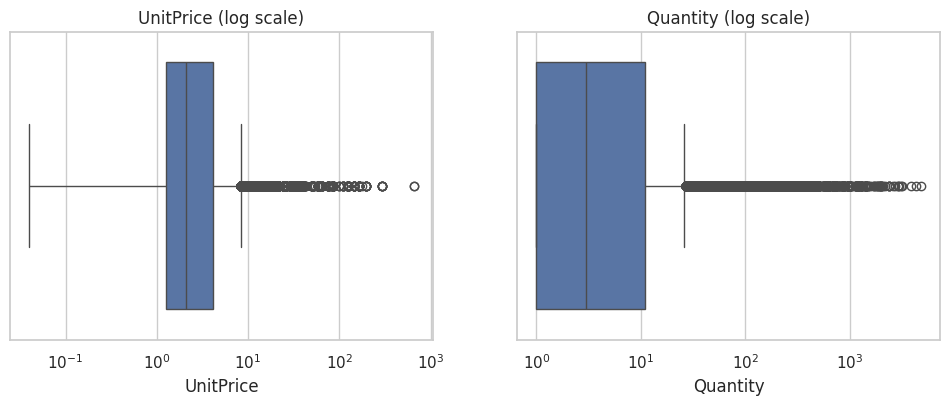

In [30]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    low, high = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    print(f"{s.name}: bounds [{low:.2f}, {high:.2f}], outliers {((s < low) | (s > high)).sum():,}")
    return (s < low) | (s > high)


df_sales["PriceOutlier"] = iqr_outliers(df_sales["UnitPrice"])
df_sales["QuantityOutlier"] = iqr_outliers(df_sales["Quantity"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["UnitPrice", "Quantity"]):
    sns.boxplot(x=df_sales[col], ax=ax)
    ax.set_xscale("log")
    ax.set_title(f"{col} (log scale)")
plt.show()

## 5. Star schema
Grain of the fact table: one product line on an invoice. Sales without a customer ID are kept under
`CustomerKey = 0` ("Unknown"), so warehouse totals match total net sales.

In [31]:
# Customer dimension
known = df_sales.dropna(subset=["CustomerID"])
dim_customer = (known.groupby("CustomerID")["Country"].agg(lambda s: s.mode().iat[0])
                .rename("PrimaryCountry").reset_index())
dim_customer.insert(0, "CustomerKey", np.arange(1, len(dim_customer) + 1))
unknown = pd.DataFrame({"CustomerKey": [0], "CustomerID": pd.array([pd.NA], dtype="Int64"),
                        "PrimaryCountry": ["Unknown"]})
dim_customer = pd.concat([unknown, dim_customer], ignore_index=True)

# Product dimension
dim_product = (df_sales.groupby("StockCode")
               .agg(Description=("Description", "first"), MedianUnitPrice=("UnitPrice", "median"))
               .reset_index())
dim_product.insert(0, "ProductKey", np.arange(1, len(dim_product) + 1))

# Country dimension (country of the sale)
dim_country = pd.DataFrame({"Country": sorted(df_sales["Country"].unique())})
dim_country.insert(0, "CountryKey", np.arange(1, len(dim_country) + 1))

# Date dimension: a full calendar, including days without sales
days = pd.date_range(df_sales["InvoiceDate"].min().normalize(),
                     df_sales["InvoiceDate"].max().normalize(), freq="D")
dim_date = pd.DataFrame({
    "DateKey": days.strftime("%Y%m%d").astype(int), "Date": days, "Year": days.year,
    "Quarter": days.quarter, "Month": days.month, "MonthName": days.month_name(),
    "Day": days.day, "DayName": days.day_name(), "IsWeekend": days.dayofweek >= 5})
dim_date["HasSales"] = dim_date["Date"].isin(df_sales["InvoiceDate"].dt.normalize())

# Fact table
fact_sales = df_sales.copy()
fact_sales["CustomerKey"] = (fact_sales["CustomerID"]
                             .map(dim_customer.dropna(subset=["CustomerID"])
                                  .set_index("CustomerID")["CustomerKey"])
                             .fillna(0).astype(int))
fact_sales["ProductKey"] = fact_sales["StockCode"].map(dim_product.set_index("StockCode")["ProductKey"])
fact_sales["CountryKey"] = fact_sales["Country"].map(dim_country.set_index("Country")["CountryKey"])
fact_sales["DateKey"] = fact_sales["InvoiceDate"].dt.strftime("%Y%m%d").astype(int)
fact_sales["Hour"] = fact_sales["InvoiceDate"].dt.hour
fact_sales["SalesKey"] = np.arange(1, len(fact_sales) + 1)
fact_sales = fact_sales[["SalesKey", "InvoiceNo", "CustomerKey", "ProductKey", "DateKey",
                         "CountryKey", "Hour", "Quantity", "UnitPrice", "TotalAmount"]]

# Validation
for dim, key in [(dim_customer, "CustomerKey"), (dim_product, "ProductKey"),
                 (dim_date, "DateKey"), (dim_country, "CountryKey")]:
    assert dim[key].is_unique, f"{key} is not unique"
    assert fact_sales[key].isin(dim[key]).all(), f"{key} has unmatched facts"
assert len(fact_sales) == len(df_sales)
assert np.isclose(fact_sales["TotalAmount"].sum(), df_sales["TotalAmount"].sum())
print("Star schema validated.")
for name, table in [("fact_sales", fact_sales), ("dim_customer", dim_customer),
                    ("dim_product", dim_product), ("dim_date", dim_date),
                    ("dim_country", dim_country)]:
    print(f"{name:13s}{table.shape}")
display(fact_sales.head())

Star schema validated.
fact_sales   (519815, 10)
dim_customer (4325, 3)
dim_product  (3793, 4)
dim_date     (374, 10)
dim_country  (38, 2)


,SalesKey,InvoiceNo,CustomerKey,ProductKey,DateKey,CountryKey,Hour,Quantity,UnitPrice,TotalAmount
0,1,536365,4004,3305,20101201,37,8,6,2.55,15.30
1,2,536365,4004,2707,20101201,37,8,6,3.39,20.34
2,3,536365,4004,2912,20101201,37,8,8,2.75,22.00
3,4,536365,4004,2859,20101201,37,8,6,3.39,20.34
4,5,536365,4004,2858,20101201,37,8,6,3.39,20.34


## 6. OLAP operations
The data starts in December 2010 and ends partway through December 2011, so yearly totals are not comparable.

In [32]:
cube = (fact_sales.merge(dim_date, on="DateKey", validate="many_to_one")
        .merge(dim_country, on="CountryKey", validate="many_to_one"))
measures = dict(Revenue=("TotalAmount", "sum"), Quantity=("Quantity", "sum"),
                Invoices=("InvoiceNo", "nunique"))

print("Roll-up: year")
display(cube.groupby("Year").agg(**measures))
print("Drill-down: year > quarter > month")
monthly = cube.groupby(["Year", "Quarter", "Month"]).agg(**measures)
display(monthly)

Roll-up: year


,Revenue,Quantity,Invoices
Year,,,
2010,760990.88,352085,1541
2011,9043884.31,4962858,18106


Drill-down: year > quarter > month


Revenue  Quantity  Invoices
Year Quarter Month                                
2010 4       12      760990.88    352085      1541
2011 1       1       562190.52    300106      1073
             2       501181.01    280730      1089
             3       678386.06    371035      1431
     2       4       508915.10    303933      1227
             5       728318.67    389433      1652
             6       723675.63    380258      1511
     3       7       677781.33    394541      1445
             8       702819.12    410155      1335
             9      1014402.00    563528      1808
     4       10     1065715.57    599652      1985
             11     1435611.94    738435      2739
             12      444887.36    231052       811

In [33]:
year = 2011
print(f"Slice: Year = {year}")
display(cube[cube["Year"] == year].groupby(["Month", "MonthName"]).agg(**measures))

# Dice: Q1 2011 invoices whose TOTAL value exceeds 100
invoice_total = cube.groupby("InvoiceNo")["TotalAmount"].transform("sum")
dice = cube[(cube["Year"] == year) & (cube["Quarter"] == 1) & (invoice_total > 100)]
print("Dice: 2011, Q1, invoice total > 100")
display(dice.groupby(["Month", "MonthName"]).agg(**measures))

print("Pivot: revenue by year and month (blank = no data)")
display(cube.pivot_table(index="Year", columns="Month", values="TotalAmount", aggfunc="sum").round(0))

Slice: Year = 2011


,,Revenue,Quantity,Invoices
Month,MonthName,,,
1,January,562190.52,300106,1073
2,February,501181.01,280730,1089
3,March,678386.06,371035,1431
4,April,508915.10,303933,1227
5,May,728318.67,389433,1652
6,June,723675.63,380258,1511
7,July,677781.33,394541,1445
8,August,702819.12,410155,1335
9,September,1014402.00,563528,1808


Dice: 2011, Q1, invoice total > 100


,,Revenue,Quantity,Invoices
Month,MonthName,,,
1,January,557437.00,296939,958
2,February,494971.80,276378,951
3,March,669428.56,366327,1235


Pivot: revenue by year and month (blank = no data)


Month,1,2,3,4,5,6,7,8,9,10,11,12
Year,,,,,,,,,,,,
2010,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,760991.0
2011,562191.0,501181.0,678386.0,508915.0,728319.0,723676.0,677781.0,702819.0,1014402.0,1065716.0,1435612.0,444887.0


## 7. Sales analysis

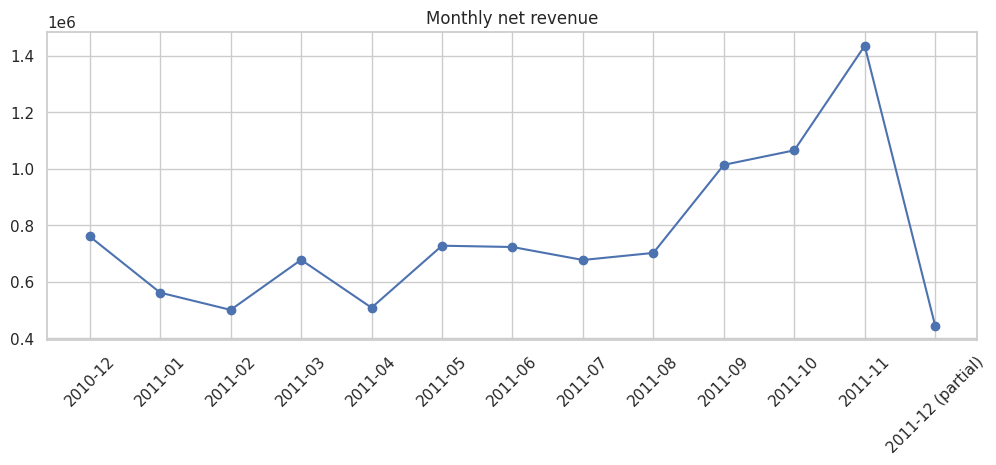

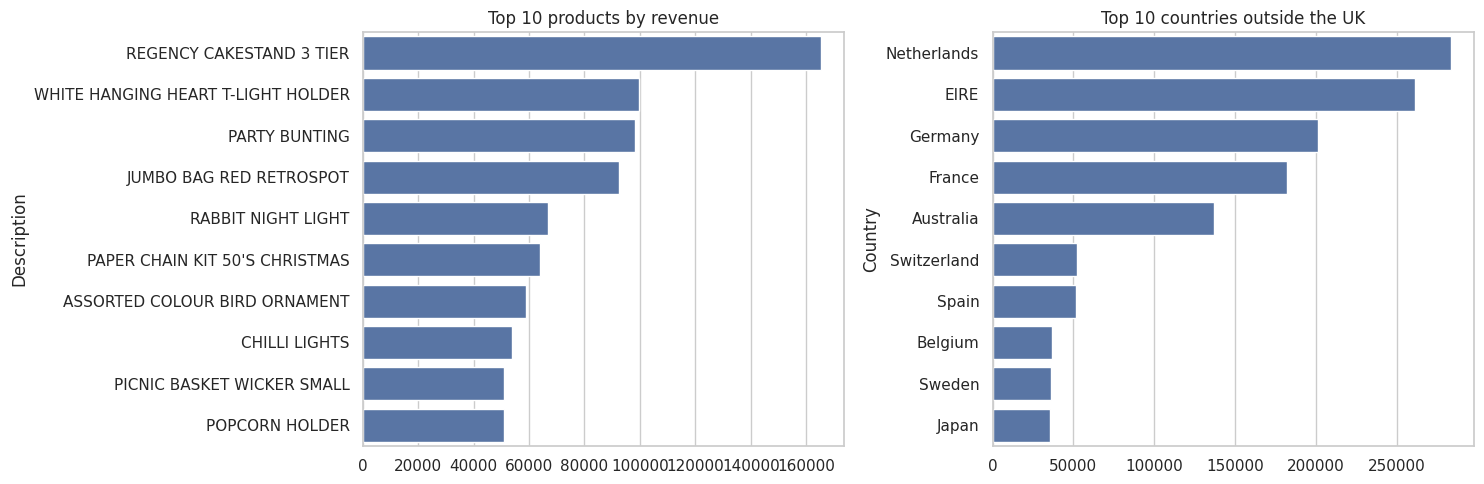

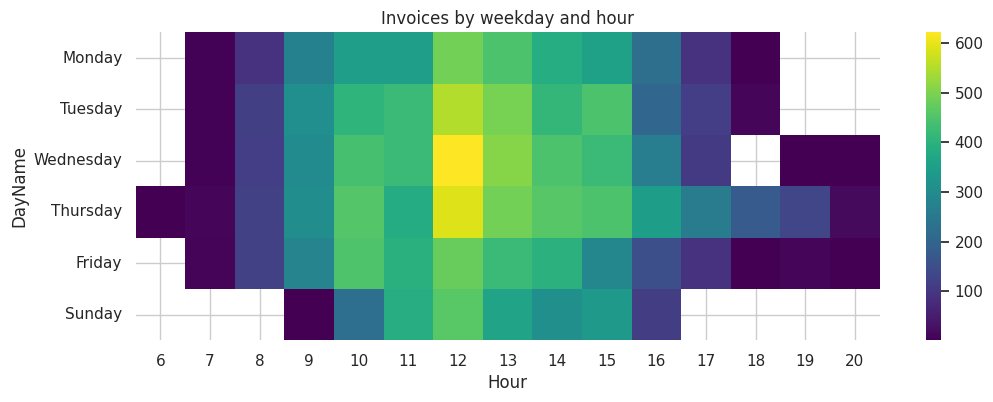

In [34]:
trend = cube.groupby(cube["Date"].dt.to_period("M"))["TotalAmount"].sum()
labels = trend.index.astype(str).tolist()
if cube["Date"].max().day < cube["Date"].max().days_in_month:
    labels[-1] += " (partial)"
plt.figure(figsize=(12, 4))
plt.plot(labels, trend.values, marker="o")
plt.title("Monthly net revenue")
plt.xticks(rotation=45)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
top_products = (cube.merge(dim_product[["ProductKey", "Description"]], on="ProductKey")
                .groupby("Description")["TotalAmount"].sum().nlargest(10))
sns.barplot(x=top_products.values, y=top_products.index, ax=axes[0])
axes[0].set_title("Top 10 products by revenue")
top_countries = (cube[cube["Country"] != "United Kingdom"]
                 .groupby("Country")["TotalAmount"].sum().nlargest(10))
sns.barplot(x=top_countries.values, y=top_countries.index, ax=axes[1])
axes[1].set_title("Top 10 countries outside the UK")
plt.tight_layout()
plt.show()

heat = cube.pivot_table(index="DayName", columns="Hour", values="InvoiceNo", aggfunc="nunique")
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
plt.figure(figsize=(12, 4))
sns.heatmap(heat.reindex([d for d in order if d in heat.index]), cmap="viridis")
plt.title("Invoices by weekday and hour")
plt.show()

## 8. Customer analysis
### 8.1 RFM scoring
Scores run from 1 (weakest) to 5 (strongest). Customers with equal values always get the same score.
Average order value is the mean **invoice** total.

,Customers,AvgRecency,AvgFrequency,Revenue
Segment,,,,
Champions,1017,13.1,10.6,5543048.0
Loyal,1050,35.2,3.4,1357182.5
At Risk,755,154.4,3.2,855259.5
Hibernating or Occasional,1266,183.4,1.0,464476.7
New or Promising,236,19.4,1.0,74916.8


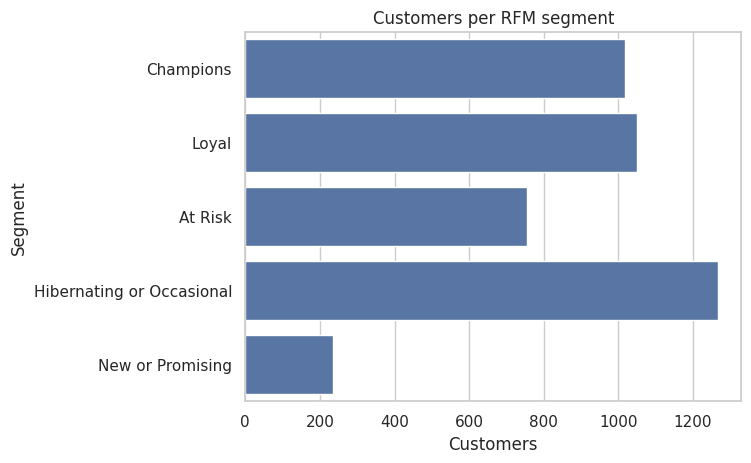

In [35]:
invoices = (known.groupby(["CustomerID", "InvoiceNo"])
            .agg(OrderValue=("TotalAmount", "sum"), Units=("Quantity", "sum"),
                 OrderDate=("InvoiceDate", "min")).reset_index())
snapshot = df_sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)
rfm = (invoices.groupby("CustomerID")
       .agg(Frequency=("InvoiceNo", "nunique"), Monetary=("OrderValue", "sum"),
            AverageOrderValue=("OrderValue", "mean"), AverageUnitsPerOrder=("Units", "mean"),
            LastPurchase=("OrderDate", "max")).reset_index())
rfm["Recency"] = (snapshot - rfm["LastPurchase"].dt.normalize()).dt.days


def score(s, higher_is_better=True):
    pct = s.rank(method="average", pct=True, ascending=higher_is_better)
    return np.ceil(pct * 5).clip(1, 5).astype(int)


rfm["R"] = score(rfm["Recency"], higher_is_better=False)
rfm["F"] = score(rfm["Frequency"])
rfm["M"] = score(rfm["Monetary"])
rfm["Segment"] = np.select(
    [(rfm.R >= 4) & (rfm.F >= 4), (rfm.R >= 3) & (rfm.F >= 3), (rfm.R >= 4),
     (rfm.R <= 2) & (rfm.F >= 3)],
    ["Champions", "Loyal", "New or Promising", "At Risk"], default="Hibernating or Occasional")
segment_summary = (rfm.groupby("Segment")
                   .agg(Customers=("CustomerID", "size"), AvgRecency=("Recency", "mean"),
                        AvgFrequency=("Frequency", "mean"), Revenue=("Monetary", "sum"))
                   .sort_values("Revenue", ascending=False))
display(segment_summary.round(1))
sns.barplot(x=segment_summary["Customers"], y=segment_summary.index)
plt.title("Customers per RFM segment")
plt.show()

### 8.2 K-Means clustering

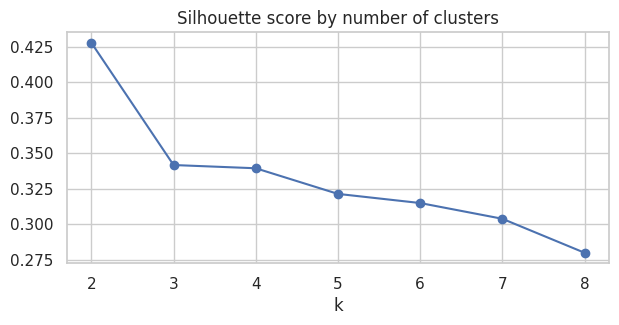

,Recency,Frequency,Monetary
Cluster,,,
0,55.0,4.0,1304.040
1,179.0,1.0,287.500
2,18.0,2.0,455.955
3,9.0,10.0,3610.615


Cluster
0    1183
1    1599
2     846
3     696
Name: count, dtype: int64

In [36]:
X_cluster = StandardScaler().fit_transform(np.log1p(rfm[["Recency", "Frequency", "Monetary"]]))
ks = range(2, 9)
silhouettes = [silhouette_score(X_cluster, KMeans(k, n_init=10, random_state=SEED).fit_predict(X_cluster),
                                sample_size=min(3000, len(X_cluster)), random_state=SEED) for k in ks]
plt.figure(figsize=(7, 3))
plt.plot(list(ks), silhouettes, marker="o")
plt.title("Silhouette score by number of clusters")
plt.xlabel("k")
plt.show()

# k=4 gives more useful business groups than very small k; compare with the plot above
K = 4
rfm["Cluster"] = KMeans(K, n_init=10, random_state=SEED).fit_predict(X_cluster)
display(rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].median())
display(rfm["Cluster"].value_counts().sort_index())

### 8.3 Cohort retention
The first cohort includes customers who were already buying before the data begins.

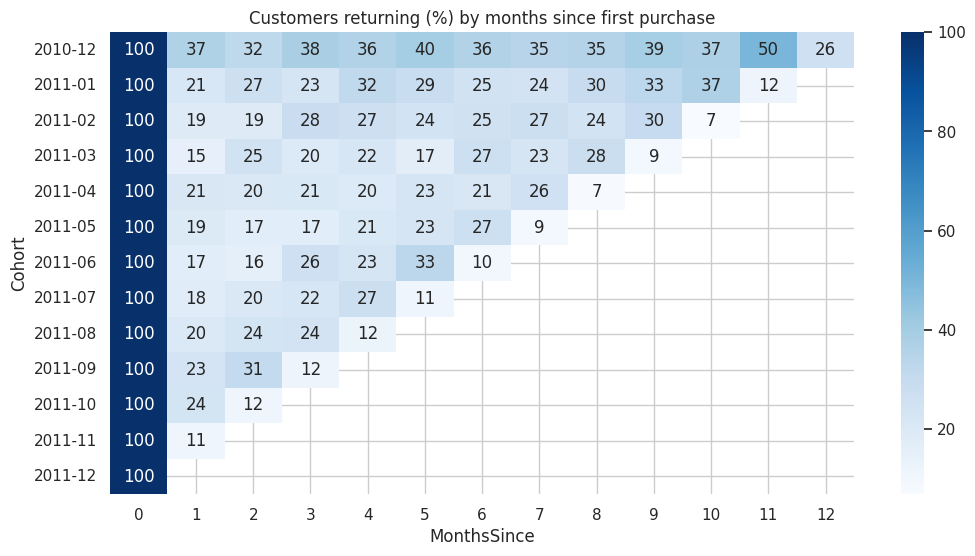

In [37]:
inv = invoices.assign(Month=invoices["OrderDate"].dt.to_period("M"))
inv["Cohort"] = inv.groupby("CustomerID")["Month"].transform("min")
inv["MonthsSince"] = ((inv["Month"].dt.year - inv["Cohort"].dt.year) * 12
                      + (inv["Month"].dt.month - inv["Cohort"].dt.month))
cohort = inv.pivot_table(index="Cohort", columns="MonthsSince", values="CustomerID", aggfunc="nunique")
retention = cohort.div(cohort[0], axis=0) * 100
retention.index = retention.index.astype(str)
plt.figure(figsize=(12, 6))
sns.heatmap(retention, annot=True, fmt=".0f", cmap="Blues")
plt.title("Customers returning (%) by months since first purchase")
plt.show()

## 9. Market basket analysis
Pairs among the 200 most frequently bought products. **Support**: share of invoices with both items.
**Confidence**: share of invoices with A that also contain B. **Lift** above 1: bought together more than chance.

In [38]:
top_codes = df_sales.groupby("StockCode")["InvoiceNo"].nunique().nlargest(200).index
basket = df_sales[df_sales["StockCode"].isin(top_codes)][["InvoiceNo", "StockCode"]].drop_duplicates()
rows = basket["InvoiceNo"].astype("category")
cols = basket["StockCode"].astype("category")
matrix = sparse.csr_matrix((np.ones(len(basket)), (rows.cat.codes, cols.cat.codes)))
together = (matrix.T @ matrix).toarray()
n = df_sales["InvoiceNo"].nunique()
item_count = together.diagonal()
a, b = np.nonzero((together / n >= 0.01) & ~np.eye(len(item_count), dtype=bool))
names = description_map.reindex(cols.cat.categories).to_numpy()
rules = pd.DataFrame({"If bought": names[a], "Also bought": names[b],
                      "Support": together[a, b] / n,
                      "Confidence": together[a, b] / item_count[a],
                      "Lift": together[a, b] * n / (item_count[a] * item_count[b])})
rules = rules[rules["Confidence"] >= 0.3].sort_values("Lift", ascending=False)
print("Rules found:", len(rules))
display(rules.head(15).round(3))

Rules found: 555


,If bought,Also bought,Support,Confidence,Lift
883,WOODEN STAR CHRISTMAS SCANDINAVIAN,WOODEN HEART CHRISTMAS SCANDINAVIAN,0.020,0.758,27.674
882,WOODEN HEART CHRISTMAS SCANDINAVIAN,WOODEN STAR CHRISTMAS SCANDINAVIAN,0.020,0.721,27.674
1022,HAND WARMER BIRD DESIGN,HAND WARMER SCOTTY DOG DESIGN,0.014,0.515,18.513
1020,HAND WARMER SCOTTY DOG DESIGN,HAND WARMER BIRD DESIGN,0.014,0.519,18.513
1019,HAND WARMER SCOTTY DOG DESIGN,HAND WARMER OWL DESIGN,0.017,0.607,18.431
1016,HAND WARMER OWL DESIGN,HAND WARMER SCOTTY DOG DESIGN,0.017,0.513,18.431
1373,SINGLE HEART ZINC T-LIGHT HOLDER,HANGING HEART ZINC T-LIGHT HOLDER,0.014,0.553,18.030
1374,HANGING HEART ZINC T-LIGHT HOLDER,SINGLE HEART ZINC T-LIGHT HOLDER,0.014,0.464,18.030
1351,WOOD S/3 CABINET ANT WHITE FINISH,WOOD 2 DRAWER CABINET WHITE FINISH,0.014,0.460,16.946
1348,WOOD 2 DRAWER CABINET WHITE FINISH,WOOD S/3 CABINET ANT WHITE FINISH,0.014,0.514,16.946


## 10. Churn prediction
**Churn = no purchase in the 90 days after the cutoff date.** Features use only transactions and
cancellations dated before the cutoff, so no future information reaches the model.

In [39]:
WINDOW = pd.Timedelta(days=90)
end_date = df_sales["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)


def churn_dataset(cutoff):
    past = lambda t: t[(t["InvoiceDate"] < cutoff) & t["CustomerID"].notna()]
    hist, _, _ = net_cancellations(past(sales_raw), past(cancels))
    g = hist.groupby("CustomerID")
    X = g.agg(TotalOrders=("InvoiceNo", "nunique"), TotalQuantity=("Quantity", "sum"),
              TotalRevenue=("TotalAmount", "sum"), AverageUnitPrice=("UnitPrice", "mean"),
              UniqueProducts=("StockCode", "nunique"), First=("InvoiceDate", "min"),
              Last=("InvoiceDate", "max"), Country=("Country", "first"))
    X["AverageOrderValue"] = X["TotalRevenue"] / X["TotalOrders"]
    X["Recency"] = (cutoff - X["Last"]).dt.days
    X["Tenure"] = (cutoff - X["First"]).dt.days
    X["OrdersPerMonth"] = X["TotalOrders"] / (X["Tenure"].clip(lower=30) / 30)
    for d in (30, 90):
        recent = hist[hist["InvoiceDate"] >= cutoff - pd.Timedelta(days=d)]
        X[f"OrdersLast{d}Days"] = recent.groupby("CustomerID")["InvoiceNo"].nunique()
    X["CancelledOrders"] = past(cancels).groupby("CustomerID")["InvoiceNo"].nunique()
    X["IsUK"] = (X["Country"] == "United Kingdom").astype(int)
    X = X.drop(columns=["First", "Last", "Country"]).fillna(0)

    window = lambda t: t[(t["InvoiceDate"] >= cutoff) & (t["InvoiceDate"] < cutoff + WINDOW)
                         & t["CustomerID"].notna()]
    future, _, _ = net_cancellations(window(sales_raw), window(cancels))
    y = (~X.index.isin(future["CustomerID"])).astype(int)
    return X.astype(float), pd.Series(y, index=X.index, name="Churn")


cutoff_date = end_date - WINDOW
X, y = churn_dataset(cutoff_date)
print("Cutoff:", cutoff_date.date())
print("Customers:", len(X), "| Churned:", y.sum(), "| Active:", (y == 0).sum())
display(X.head())

Cutoff: 2011-09-11
Customers: 3363 | Churned: 1448 | Active: 1915


,TotalOrders,TotalQuantity,TotalRevenue,AverageUnitPrice,UniqueProducts,AverageOrderValue,Recency,Tenure,OrdersPerMonth,OrdersLast30Days,OrdersLast90Days,CancelledOrders,IsUK
CustomerID,,,,,,,,,,,,,
12347,5.0,1590.0,2790.86,2.797661,82.0,558.172000,39.0,277.0,0.541516,0.0,1.0,0.0,0.0
12348,3.0,2116.0,1167.24,0.648400,21.0,389.080000,158.0,268.0,0.335821,0.0,0.0,0.0,0.0
12350,1.0,196.0,294.40,1.581250,16.0,294.400000,220.0,220.0,0.136364,0.0,0.0,0.0,0.0
12352,3.0,186.0,521.18,4.080385,24.0,173.726667,172.0,206.0,0.436893,0.0,0.0,1.0,0.0
12353,1.0,20.0,89.00,6.075000,4.0,89.000000,114.0,114.0,0.263158,0.0,0.0,0.0,0.0


In [40]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)

models = {
    "Baseline (majority)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        FunctionTransformer(lambda a: np.sign(a) * np.log1p(np.abs(a))), StandardScaler(),
        LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                            class_weight="balanced", random_state=SEED),
    "Gradient Boosting": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                                        max_iter=150, random_state=SEED),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
table, fitted = [], {}
for name, model in models.items():
    auc_cv = cross_val_score(model, X_train, y_train, cv=cv, scoring="roc_auc")
    fitted[name] = clone(model).fit(X_train, y_train)
    pred = fitted[name].predict(X_test)
    prob = fitted[name].predict_proba(X_test)[:, 1]
    table.append({"Model": name, "CV ROC-AUC": auc_cv.mean(), "CV std": auc_cv.std(),
                  "Accuracy": accuracy_score(y_test, pred),
                  "Precision": precision_score(y_test, pred, zero_division=0),
                  "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                  "Test ROC-AUC": roc_auc_score(y_test, prob)})
comparison = pd.DataFrame(table).set_index("Model")
display(comparison.round(4))
best_name = comparison["CV ROC-AUC"].idxmax()   # chosen on training data only
best_model = fitted[best_name]
print("Selected model:", best_name)

,CV ROC-AUC,CV std,Accuracy,Precision,Recall,F1,Test ROC-AUC
Model,,,,,,,
Baseline (majority),0.5000,0.0000,0.5691,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.7524,0.0267,0.6716,0.5966,0.7345,0.6584,0.7383
Random Forest,0.7500,0.0280,0.6642,0.5904,0.7207,0.6491,0.7320
Gradient Boosting,0.7504,0.0260,0.6597,0.5981,0.6414,0.6190,0.7362


Selected model: Logistic Regression


              precision    recall  f1-score   support

      Active       0.76      0.62      0.68       383
     Churned       0.60      0.73      0.66       290

    accuracy                           0.67       673
   macro avg       0.68      0.68      0.67       673
weighted avg       0.69      0.67      0.67       673



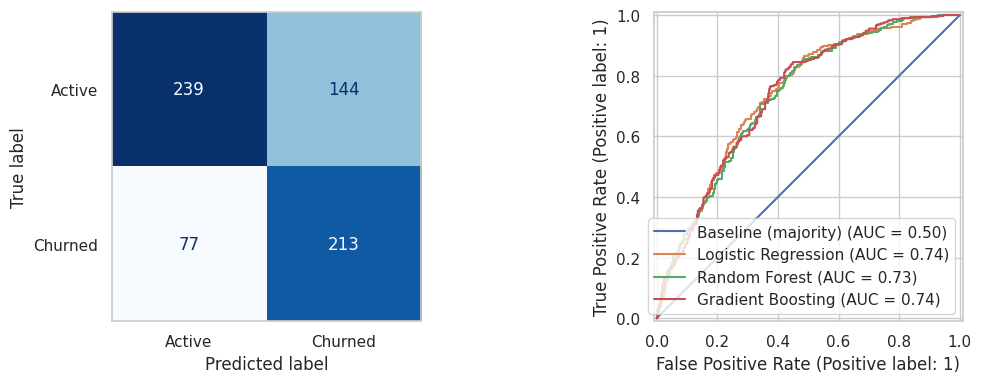

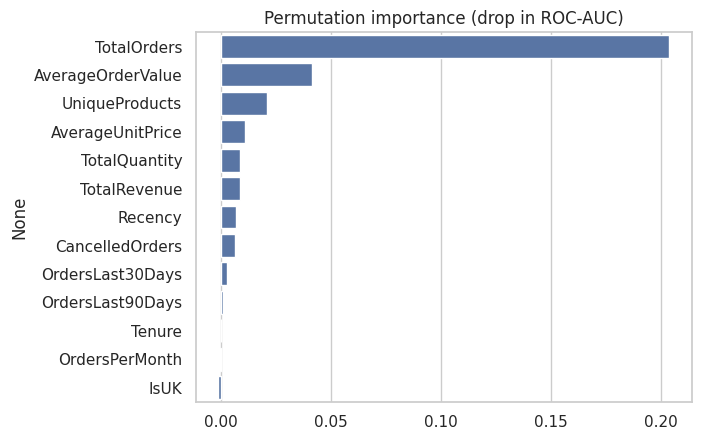

In [41]:
print(classification_report(y_test, best_model.predict(X_test), target_names=["Active", "Churned"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, display_labels=["Active", "Churned"],
                                      ax=axes[0], cmap="Blues", colorbar=False)
axes[0].grid(False)
for name, model in fitted.items():
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=axes[1])
plt.tight_layout()
plt.show()

result = permutation_importance(best_model, X_test, y_test, scoring="roc_auc",
                                n_repeats=20, random_state=SEED)
importance = pd.Series(result.importances_mean, index=X.columns).sort_values(ascending=False)
sns.barplot(x=importance.values, y=importance.index)
plt.title("Permutation importance (drop in ROC-AUC)")
plt.show()

### 10.1 Check on a later time period
Train on an earlier cutoff, then test on the final one. This is closer to real use. The same customers
appear in both periods, and the earlier window has less history.

In [42]:
X_early, y_early = churn_dataset(cutoff_date - WINDOW)
later = clone(models[best_name]).fit(X_early, y_early)
print("Train customers:", len(X_early), "| Test customers:", len(X))
print("Out-of-time ROC-AUC:", round(roc_auc_score(y, later.predict_proba(X)[:, 1]), 4))
print("Out-of-time accuracy:", round(accuracy_score(y, later.predict(X)), 4))

Train customers: 2814 | Test customers: 3363
Out-of-time ROC-AUC: 0.7434
Out-of-time accuracy: 0.6711


In [43]:
# Out-of-fold scores: each customer is scored by a model that did not train on them
churn_scores = pd.DataFrame({
    "CustomerID": X.index, "ActualChurn": y.values,
    "ChurnProbability": cross_val_predict(clone(models[best_name]), X, y, cv=cv,
                                          method="predict_proba")[:, 1]})

# Segment and revenue as they stood at the cutoff (X holds only pre-cutoff data)
R = score(X["Recency"], higher_is_better=False)
F = score(X["TotalOrders"])
churn_scores["SegmentAtCutoff"] = np.select(
    [(R >= 4) & (F >= 4), (R >= 3) & (F >= 3), R >= 4, (R <= 2) & (F >= 3)],
    ["Champions", "Loyal", "New or Promising", "At Risk"], default="Hibernating or Occasional")
churn_scores["RevenueBeforeCutoff"] = X["TotalRevenue"].values

print("High-value customers (top 25% before cutoff) with the highest churn risk")
high_value = churn_scores["RevenueBeforeCutoff"] >= churn_scores["RevenueBeforeCutoff"].quantile(0.75)
display(churn_scores[high_value].nlargest(10, "ChurnProbability"))

High-value customers (top 25% before cutoff) with the highest churn risk


,CustomerID,ActualChurn,ChurnProbability,SegmentAtCutoff,RevenueBeforeCutoff
1592,15098,1,0.836274,Loyal,39619.50
2513,16754,1,0.803814,Hibernating or Occasional,2002.40
474,13135,1,0.749018,Hibernating or Occasional,3096.00
60,12435,0,0.740278,Hibernating or Occasional,3978.99
1214,14439,1,0.726704,Hibernating or Occasional,2661.24
1504,14935,1,0.719015,Hibernating or Occasional,1784.71
2942,17553,1,0.711236,New or Promising,1487.60
266,12770,1,0.705026,Hibernating or Occasional,1351.45
2463,16671,0,0.704109,Hibernating or Occasional,1382.88
2183,16152,1,0.704099,Hibernating or Occasional,1829.04


## 11. Data quality checks and export

In [44]:
outputs = {"fact_sales": fact_sales, "dim_customer": dim_customer, "dim_product": dim_product,
           "dim_date": dim_date, "dim_country": dim_country, "customer_rfm": rfm,
           "market_basket_rules": rules, "churn_scores": churn_scores}
display(pd.DataFrame({name: {"Rows": len(t), "Columns": t.shape[1],
                             "Missing cells": int(t.isnull().sum().sum()),
                             "Duplicate rows": int(t.duplicated().sum())}
                      for name, t in outputs.items()}).T)
print("The single expected missing cell is CustomerID of the Unknown customer.")

output_dir = "/kaggle/working" if os.path.isdir("/kaggle/working") else "output"
os.makedirs(output_dir, exist_ok=True)
for name, table in outputs.items():
    table.to_csv(os.path.join(output_dir, f"{name}.csv"), index=False)
print("Saved", len(outputs), "files to", output_dir)

,Rows,Columns,Missing cells,Duplicate rows
fact_sales,519815,10,0,0
dim_customer,4325,3,1,0
dim_product,3793,4,0,0
dim_date,374,10,0,0
dim_country,38,2,0,0
customer_rfm,4324,12,0,0
market_basket_rules,555,5,0,0
churn_scores,3363,5,0,0


The single expected missing cell is CustomerID of the Unknown customer.
Saved 8 files to /kaggle/working
